<h1><center>Introduction à la cryptographie : le chiffrement de César</center></h1>

Jules César aurait utilisé ce procédé pour protéger ses messages militaires : chaque lettre est **décalée d'un nombre fixe `k` de positions** dans l'alphabet. Avec `k = 3`, `a` devient `d`, `b` devient `e`, … et `z` devient `c` (on « reboucle »).

![](media/cesar.png)

Dans ce TP, vous allez :

1. chiffrer un caractère ;
2. chiffrer un message complet ;
3. le déchiffrer ;
4. casser un message par force brute ;
5. casser un message grâce à l'analyse fréquentielle ;
6. *(bonus)* découvrir le chiffre affine.

**Remarques**
- Après chaque fonction, une cellule de tests vous dit si c'est bon. Si un `assert` échoue, relisez votre code.
- Les caractères qui ne sont pas des lettres de l'alphabet (espaces, ponctuation, chiffres) restent inchangés.
- Pour simplifier, tous les textes sont écrits sans accents.

## 1. Chiffrer un caractère

### 1.1 Découverte de `ord` et `chr`

Je vous laisser lire et la doc et jouer un peu avec les fonctions `ord` et `chr`.
- Comment fonctionnent-elles ?
- Comment obtenir la position dans l'alphabet (0 pour `a`, 1 pour `b`, …, 25 pour `z`) d'une lettre minuscule `c` ?
- Quel est le problème si on calcule simplement `chr(ord('z') + 3)` ?

In [44]:
# Votre code ici

# Q1
# ord renvoie le code ASCII d'un caractère et chr 
# renvoie le caractère à partir du code ASCII.
# Les minuscules et majuscules ont des plages de codes 
# différentes (écart de 32).

# Q2
c = 'd'
print(ord(c) - ord('a'))

# Q3
chr(ord('z') + 3)
# On sort de l'alphabet. Le modulo `% 26` permet de reboucler.

3


'}'

### 1.2 La fonction `chiffrer_caractere`

Ecrire la fonction `chiffrer_caractere(c, k)` qui :
- décale les lettres minuscules de `k` positions ;
- décale les lettres majuscules de `k` positions (en restant en majuscule) ;
- renvoie tout autre caractère inchangé.

In [45]:
def chiffrer_caractere(c, k):
    """Chiffre le caractère c avec le décalage k.
    Les caractères qui ne sont pas des lettres de a-z / A-Z sont renvoyés tels quels."""
    if 'a' <= c <= 'z':
        return chr((ord(c) - ord('a') + k) % 26 + ord('a'))
    elif 'A' <= c <= 'Z':
        return chr((ord(c) - ord('A') + k) % 26 + ord('A'))
    else:
        return c

In [46]:
assert chiffrer_caractere('a', 3) == 'd'
assert chiffrer_caractere('x', 3) == 'a', "Pensez au modulo !"
assert chiffrer_caractere('z', 1) == 'a'
assert chiffrer_caractere('A', 3) == 'D', "Les majuscules doivent rester des majuscules"
assert chiffrer_caractere('Z', 1) == 'A'
assert chiffrer_caractere('m', -3) == 'j', "k peut être négatif"
assert chiffrer_caractere('a', 29) == 'd', "k peut dépasser 26"
assert chiffrer_caractere(' ', 5) == ' '
assert chiffrer_caractere('!', 5) == '!'
assert chiffrer_caractere('7', 5) == '7'
print("Partie 1 OK")

Partie 1 OK


## 2. Chiffrer un message complet

Ecrire une fonction `chiffrer_message(message, k)` qui permet de chiffre un message complet avec un décalage `k`. 

In [47]:
def chiffrer_message(message, k):
    """Chiffre une chaîne complète avec le décalage k."""
    return ''.join(chiffrer_caractere(c, k) for c in message)

In [48]:
assert chiffrer_message("abc", 3) == "def"
assert chiffrer_message("xyz", 3) == "abc"
assert chiffrer_message("Hello, World!", 3) == "Khoor, Zruog!"
assert chiffrer_message("", 5) == ""
assert chiffrer_message("Rendez-vous a 18h", 0) == "Rendez-vous a 18h"
print("Partie 2 OK")

Partie 2 OK


## 3. Déchiffrer un message

Ecrire une fonction `dechiffrer_message(message_chiffre, k)` qui déchiffre un message codé en connaissant la clé `k`.

In [49]:
# Votre code ici

def dechiffrer_message(message_chiffre, k):
    """Déchiffre un message chiffré avec la clé k."""
    return chiffrer_message(message_chiffre, -k)

In [50]:
assert dechiffrer_message("Khoor, Zruog!", 3) == "Hello, World!"
for k in range(0, 60, 7):
    for m in ["Bonjour tout le monde !", "ZzAa", "Python 3.12"]:
        assert dechiffrer_message(chiffrer_message(m, k), k) == m, f"Échec pour k={k}, m={m!r}"
print("Partie 3 OK")

Partie 3 OK


1. Que se passe-t-il si on chiffre avec `k = 26` ? Pourquoi est-ce un mauvais choix de clé ?
2. Combien de clés « utiles » existe-t-il réellement ?
3. Pour `k = 13` (ce qu'on appelle **ROT13**), que se passe-t-il si on chiffre deux fois de suite ? Vérifiez-le avec votre code.

In [51]:
m = "Hello"

# Q1
print(chiffrer_message(m, 26))
# Le message n'est pas modifié (26 ≡ 0 mod 26).

# Q2
# Seulement 25 clés non triviales (k de 1 à 25) : 
# l'espace des clés est minuscule.
# C'est la faiblesse principale du chiffre.

# Q3
print(chiffrer_message(chiffrer_message(m, 13), 13))
# On retrouve le message d'origine : 
# ROT13 est sa propre inverse (13 + 13 = 26 ≡ 0).

Hello
Hello


## 4. Casser le code par force brute

Vous avez intercepté le message suivant. Vous savez qu'il a été chiffré avec un chiffre de César, mais **vous ne connaissez pas la clé**.

In [52]:
MESSAGE_MYSTERE = "Mlspjpahapvuz, cvbz hclg jhzzl cvayl wyltply jvkl zljyla !"

Comme il n'y a que 25 clés possibles, on peut toutes les essayer (attaque par *force brute*) et lire le résultat à la recherche de celle qui donne un texte cohérent.

Ecrire `afficher_toutes_les_cles(message_chiffre)` qui affiche, pour chaque clé `k` de 0 à 25, une ligne de la forme :

```
k=9 : Message dechiffré
```

In [53]:
# Votre code ici

def afficher_toutes_les_cles(message_chiffre):
    """Affiche le déchiffrement du message pour chacune des 26 clés."""
    
    for k in range(26):
        print(f"k={k:2d} : {dechiffrer_message(message_chiffre, k)}")

In [54]:
afficher_toutes_les_cles(MESSAGE_MYSTERE)

k= 0 : Mlspjpahapvuz, cvbz hclg jhzzl cvayl wyltply jvkl zljyla !
k= 1 : Lkroiozgzouty, buay gbkf igyyk buzxk vxksokx iujk ykixkz !
k= 2 : Kjqnhnyfyntsx, atzx faje hfxxj atywj uwjrnjw htij xjhwjy !
k= 3 : Jipmgmxexmsrw, zsyw ezid gewwi zsxvi tviqmiv gshi wigvix !
k= 4 : Iholflwdwlrqv, yrxv dyhc fdvvh yrwuh suhplhu frgh vhfuhw !
k= 5 : Hgnkekvcvkqpu, xqwu cxgb ecuug xqvtg rtgokgt eqfg ugetgv !
k= 6 : Gfmjdjubujpot, wpvt bwfa dbttf wpusf qsfnjfs dpef tfdsfu !
k= 7 : Felicitations, vous avez casse votre premier code secret !
k= 8 : Edkhbhszshnmr, untr zudy bzrrd unsqd oqdlhdq bncd rdbqds !
k= 9 : Dcjgagryrgmlq, tmsq ytcx ayqqc tmrpc npckgcp ambc qcapcr !
k=10 : Cbifzfqxqflkp, slrp xsbw zxppb slqob mobjfbo zlab pbzobq !
k=11 : Baheyepwpekjo, rkqo wrav ywooa rkpna lnaiean ykza oaynap !
k=12 : Azgdxdovodjin, qjpn vqzu xvnnz qjomz kmzhdzm xjyz nzxmzo !
k=13 : Zyfcwcnuncihm, piom upyt wummy pinly jlygcyl wixy mywlyn !
k=14 : Yxebvbmtmbhgl, ohnl toxs vtllx ohmkx ikxfbxk vhwx lxvkxm !
k=15 : Xwd

Quelle est la clé ? Notez-la dans la cellule suivante, puis lancez le test.

In [55]:
# Votre code ici

CLE_TROUVEE = 7

In [56]:
assert CLE_TROUVEE is not None, "Renseignez la clé trouvée"
assert "secret" in dechiffrer_message(MESSAGE_MYSTERE, CLE_TROUVEE).lower(), "Ce n'est pas la bonne clé"
print("Partie 4 OK")

Partie 4 OK


Ici, c'est vous qui avez lu les 26 candidats pour trouver le bon. Que se passerait-il si on devait casser 10 000 messages ? Comment faire choisir le bon candidat automatiquement ? C'est ce qu'on va voir dans la partie suivante.

## 5. Analyse fréquentielle

Dans un texte français, les lettres n'apparaissent pas avec la même fréquence : le `e` est de loin la lettre la plus courante (≈ 15 %). Or, un chiffre de César remplace toujours une lettre par la même lettre : la lettre la plus fréquente du texte chiffré est donc très probablement l'image du `e`. Cela suffit à retrouver la clé !

### 5.1 Compter les lettres

Ecrire `compter_lettres(texte)` qui renvoie un dictionnaire `{lettre: nombre d'occurrences}`.
- on ne compte que les lettres `a`–`z`, **sans distinguer majuscules et minuscules** ;
- seules les lettres présentes dans le texte apparaissent dans le dictionnaire.

In [57]:
# Votre code ici

def compter_lettres(texte):
    """Renvoie un dictionnaire {lettre: nb d'occurrences} (a-z uniquement, insensible à la casse)."""
    
    compteur = {}
    for c in texte.lower():
        if 'a' <= c <= 'z':
            compteur[c] = compteur.get(c, 0) + 1
    return compteur

In [58]:
assert compter_lettres("Aab!") == {'a': 2, 'b': 1}
assert compter_lettres("") == {}
assert compter_lettres("1 2 3 ?!") == {}
assert compter_lettres("Eee EEe") == {'e': 6}
print("Partie 5.1 OK")

Partie 5.1 OK


### 5.2 Deviner la clé
1. Ecrire `lettre_plus_frequente(texte)` qui renvoie la lettre la plus fréquente.
2. Ecrire `deviner_cle(texte_chiffre)` qui suppose que cette lettre est l'image de `'e'` et en déduit la clé `k` (entre 0 et 25).

*Indication : Pour trouver le maximum d'un dictionnaire : `max(d, key=d.get)`.*

In [59]:
# Votre code ici

def lettre_plus_frequente(texte):
    """Renvoie la lettre (a-z) la plus fréquente du texte."""
    
    compteur = compter_lettres(texte)
    return max(compteur, key=compteur.get)

def deviner_cle(texte_chiffre):
    """Devine la clé de César en supposant que la lettre la plus fréquente correspond à 'e'."""

    L = lettre_plus_frequente(texte_chiffre)
    return (ord(L) - ord('e')) % 26

In [60]:
assert lettre_plus_frequente("abcbd") == 'b'
assert lettre_plus_frequente("Zzz a") == 'z'

TEXTE_REF = ("Les etudiants des Mines passent beaucoup de temps a programmer en Python, "
             "et cela leur permet de decouvrir progressivement des notions de plus en plus "
             "complexes de l'informatique.")
for k in [0, 3, 12, 25]:
    assert deviner_cle(chiffrer_message(TEXTE_REF, k)) == k, f"Échec pour k={k}"
print("Prtie 5.2 OK")

Prtie 5.2 OK


3. Voici un texte plus long, chiffré avec une clé inconnue. Cassez-le automatiquement avec vos fonctions.

In [61]:
TEXTE_LONG_CHIFFRE = "Cr tipgkfxirgyzv vjk c'rik uv gifkvxvi le dvjjrxv gfli hlv jvlc jfe uvjkzerkrziv glzjjv cv cziv. Uvglzj c'rekzhlzkv, cvj yfddvj fek tyvityv uvj dfpvej uv trtyvi cvlij jvtivkj. Alcvj Tvjri lkzczjrzk le giftvuv kivj jzdgcv : zc uvtrcrzk tyrhlv cvkkiv uv jfe dvjjrxv u'le efdsiv wzov uv gfjzkzfej urej c'rcgyrsvk. Tv giftvuv vjk wrtzcv r dvkkiv ve fvlmiv, drzj zc vjk rljjz kivj wrtzcv r trjjvi, tri zc e'vozjkv hlv mzexk-tzeh uvtrcrxvj gfjjzscvj. Uv gclj, tyrhlv cvkkiv vjk kflaflij ivdgcrtvv gri cr dvdv cvkkiv, tv hlz tfejvimv cvj jkrkzjkzhlvj uv cr crexlv u'fizxzev. Ve wiretrzj, cr cvkkiv cr gclj wivhlvekv vjk cv v, jlzmzv ul r, ul j, ul z vk ul e. Le rkkrhlrek grkzvek gvlk ufet ivkiflmvi cr tcv jzdgcvdvek ve tfdgkrek cvj cvkkivj ul kvokv tyzwwiv."

In [62]:
# Votre code ici

cle = deviner_cle(TEXTE_LONG_CHIFFRE)
print(cle)
print(dechiffrer_message(TEXTE_LONG_CHIFFRE, cle))

17
La cryptographie est l'art de proteger un message pour que seul son destinataire puisse le lire. Depuis l'antiquite, les hommes ont cherche des moyens de cacher leurs secrets. Jules Cesar utilisait un procede tres simple : il decalait chaque lettre de son message d'un nombre fixe de positions dans l'alphabet. Ce procede est facile a mettre en oeuvre, mais il est aussi tres facile a casser, car il n'existe que vingt-cinq decalages possibles. De plus, chaque lettre est toujours remplacee par la meme lettre, ce qui conserve les statistiques de la langue d'origine. En francais, la lettre la plus frequente est le e, suivie du a, du s, du i et du n. Un attaquant patient peut donc retrouver la cle simplement en comptant les lettres du texte chiffre.


Pour visualiser pourquoi ça marche, la cellule suivante (rien à compléter) trace la répartition des lettres du texte chiffré.

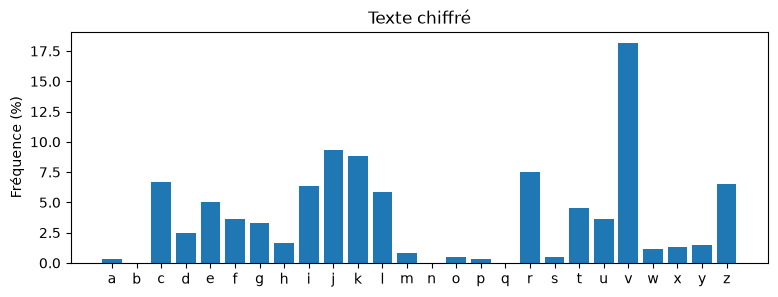

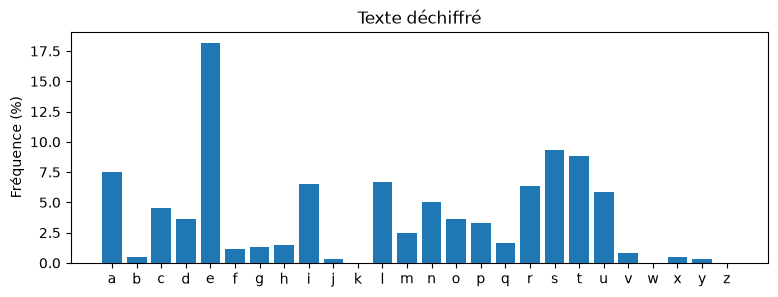

In [63]:
import matplotlib.pyplot as plt

def tracer_frequences(texte, titre=""):
    compteur = compter_lettres(texte)
    total = sum(compteur.values())
    alphabet = "abcdefghijklmnopqrstuvwxyz"
    valeurs = [100 * compteur.get(c, 0) / total for c in alphabet]
    plt.figure(figsize=(9, 3))
    plt.bar(list(alphabet), valeurs)
    plt.ylabel("Fréquence (%)")
    plt.title(titre)
    plt.show()

tracer_frequences(TEXTE_LONG_CHIFFRE, "Texte chiffré")
tracer_frequences(dechiffrer_message(TEXTE_LONG_CHIFFRE, cle) if cle is not None else "a", "Texte déchiffré")

4. Que remarquez-vous en comparant les deux graphiques ?
5. Essayez `deviner_cle(chiffrer_message("Salut", 4))` ou sur un autre message très court. Que se passe-t-il ? Pourquoi ?

In [64]:
# Votre réponse ici

# 4. Le deuxième graphique est le premier décalé de `k` positions 
# (même forme, pics aux mêmes hauteurs) : 
# un chiffre de César ne change pas les statistiques, il les translate.

# 5. La méthode échoue sur les textes courts : 
# avec peu de lettres, la statistique n'est pas 
# représentative (ex. « Salut » : toutes les lettres 
# sont à égalité, `e` n'apparaît même pas). 
# L'analyse fréquentielle demande un texte suffisamment long

### 5.3 *(Pour aller plus loin)* Un critère plus robuste

Se fier à une seule lettre est fragile. On peut faire mieux : pour chaque clé candidate, on déchiffre, puis on calcule un **score de « francité »** en sommant la fréquence théorique en français de chaque lettre du texte obtenu. Le candidat au meilleur score gagne.

La table `FREQ_FR` ci-dessous (fréquences en %) est fournie.  

Ecrire `score_francais(texte)` et `casser_par_score(message_chiffre)` qui renvoie la meilleure clé.

In [65]:
FREQ_FR = {
    'a': 7.64, 'b': 0.90, 'c': 3.26, 'd': 3.67, 'e': 14.72, 'f': 1.07, 'g': 0.87,
    'h': 0.74, 'i': 7.53, 'j': 0.61, 'k': 0.05, 'l': 5.46, 'm': 2.97, 'n': 7.10,
    'o': 5.38, 'p': 3.02, 'q': 1.36, 'r': 6.55, 's': 7.95, 't': 7.24, 'u': 6.31,
    'v': 1.63, 'w': 0.04, 'x': 0.43, 'y': 0.31, 'z': 0.14,
}

In [66]:
# Votre code ici

def score_francais(texte):
    """Somme des fréquences françaises des lettres du texte."""

    return sum(FREQ_FR.get(c, 0) for c in texte.lower())

def casser_par_score(message_chiffre):
    """Renvoie la clé k (0-25) dont le déchiffrement a le meilleur score_francais."""
    
    meilleure_cle, meilleur_score = 0, -1
    for k in range(26):
        s = score_francais(dechiffrer_message(message_chiffre, k))
        if s > meilleur_score:
            meilleure_cle, meilleur_score = k, s
    return meilleure_cle

In [67]:
assert casser_par_score(TEXTE_LONG_CHIFFRE) == deviner_cle(TEXTE_LONG_CHIFFRE)
cle_myst = casser_par_score(MESSAGE_MYSTERE)
assert "secret" in dechiffrer_message(MESSAGE_MYSTERE, cle_myst).lower()
print("Partie 5.3 OK : la méthode par score marche sur le message mystère de la partie 4")

Partie 5.3 OK : la méthode par score marche sur le message mystère de la partie 4


## Partie 6 (bonus) : Le chiffre affine

Le chiffre de César n'a que 25 clés. Pour agrandir l'espace des clés, on peut utiliser le chiffre affine, qui utilise deux paramètres `a` et `b` :

$$E(x) = (a \cdot x + b) \bmod 26$$

où `x` est la position de la lettre dans l'alphabet (0–25). Si `a = 1`, on retrouve le chiffre de César de clé `b`.

### 6.1 Chiffrer

Ecrire `chiffrer_affine(message, a, b)` (mêmes règles que précédemment : majuscules conservées, caractères non alphabétiques inchangés).

In [68]:
# Votre code ici

def chiffrer_affine(message, a, b):
    """Chiffre message avec E(x) = (a*x + b) mod 26."""
    
    resultat = ""
    for c in message:
        if 'a' <= c <= 'z':
            resultat += chr((a * (ord(c) - ord('a')) + b) % 26 + ord('a'))
        elif 'A' <= c <= 'Z':
            resultat += chr((a * (ord(c) - ord('A')) + b) % 26 + ord('A'))
        else:
            resultat += c
    return resultat

In [69]:
assert chiffrer_affine("abc", 1, 3) == "def"      # a=1 : on retrouve César
assert chiffrer_affine("abc", 3, 5) == "fil"
assert chiffrer_affine("Hello, World!", 5, 8) == "Rclla, Oaplx!"
print("Partie 6.1 OK")

Partie 6.1 OK


### 6.2 Quelles valeurs de `a` sont autorisées ?

Exécutez la cellule ci-dessous : on chiffre tout l'alphabet avec `a = 13`, puis avec `a = 5`.

In [70]:
alphabet = "abcdefghijklmnopqrstuvwxyz"
print(chiffrer_affine(alphabet, 13, 0))
print(chiffrer_affine(alphabet, 5, 0))

ananananananananananananan
afkpuzejotydinsxchmrwbglqv


**Questions**
1. Que remarquez-vous avec `a = 13` ? Pourquoi est-ce un problème pour déchiffrer ?
2. Quelle condition doit vérifier `a` par rapport à 26 pour que le chiffrement soit réversible ? *(indice : un peu d'arithmétique...)*
3. Combien y a-t-il de valeurs valides pour `a` ? Combien de clés `(a, b)` au total ?

In [71]:
# Votr code ici

# 1. Avec a = 13, on obtient `anananan…` : 
# deux lettres différentes sont chiffrées en la 
# même lettre (la fonction n'est pas injective), 
# donc impossible de déchiffrer sans ambiguïté.

# 2. a premier avec 26

# 3. φ(26) = 12 
# valeurs : 1, 3, 5, 7, 9, 11, 15, 17, 19, 21, 23, 25
# Au total 12 × 26 = 312 clés (contre 26 pour César).

### 6.3 Déchiffrer

Pour déchiffrer, on résout `y = a·x + b (mod 26)` d'où `x = a⁻¹ · (y − b) mod 26`, où `a⁻¹` est l'**inverse modulaire** de `a` : le nombre `a'` tel que `a · a' ≡ 1 (mod 26)`.

1. écrire `inverse_modulaire(a)` qui renvoie `a'` (on cherche simplement par essais entre 0 et 25) ;
2. écrire `dechiffrer_affine(message_chiffre, a, b)`.

*Remarque: Python ≥ 3.8 sait aussi le faire directement : `pow(a, -1, 26)`. Écrivez d'abord votre version à la main, puis comparez.*

In [72]:
# Votre code ici

def inverse_modulaire(a):
    """Renvoie a' tel que (a * a') % 26 == 1, ou None si a n'est pas inversible."""
    
    for x in range(26):
        if (a * x) % 26 == 1:
            return x
    return None

def dechiffrer_affine(message_chiffre, a, b):
    """Déchiffre un message chiffré avec E(x) = (a*x + b) mod 26."""
    
    a_inv = inverse_modulaire(a)
    resultat = ""
    for c in message_chiffre:
        if 'a' <= c <= 'z':
            resultat += chr((a_inv * (ord(c) - ord('a') - b)) % 26 + ord('a'))
        elif 'A' <= c <= 'Z':
            resultat += chr((a_inv * (ord(c) - ord('A') - b)) % 26 + ord('A'))
        else:
            resultat += c
    return resultat

In [73]:
assert inverse_modulaire(5) == 21
assert inverse_modulaire(13) is None
assert inverse_modulaire(1) == 1
assert dechiffrer_affine("Rclla, Oaplx!", 5, 8) == "Hello, World!"
for a in [1, 3, 5, 7, 9, 11, 15, 17, 19, 21, 23, 25]:
    for b in [0, 4, 17]:
        assert dechiffrer_affine(chiffrer_affine("Test, Affine 42 !", a, b), a, b) == "Test, Affine 42 !"
print("Partie 6.3 OK")

Partie 6.3 OK


### 6.4 Casser un chiffre affine

Un nouveau message a été intercepté. Cette fois, il y a 312 clés à tester : on ne va pas les lire une par une ! On sait que le message contient le mot `cesar` (un « mot probable »).

Ecrire `casser_affine(message_chiffre, mot_connu)` qui renvoie la liste des triplets `(a, b, texte_dechiffre)` pour lesquels `mot_connu` apparaît dans le texte déchiffré (en minuscules).

*Indication : les valeurs de `a` valides sont celles de la question 6.3 ci-dessus. Vous pouvez les calculer avec `math.gcd`.*

In [74]:
MESSAGE_AFFINE = "Lc srwhhpcqcvz ihhwvc cuz ev fce fleu ualwxc kec sclew xc Scuip, qiwu wl pcuzc zpcu hpimwlc."

In [75]:
# Votre code ici

from math import gcd

def casser_affine(message_chiffre, mot_connu):
    """Renvoie la liste des (a, b, texte) pour lesquels mot_connu apparaît dans le texte déchiffré."""
    
    candidats = []
    for a in range(1, 26):
        if gcd(a, 26) != 1:
            continue
        for b in range(26):
            texte = dechiffrer_affine(message_chiffre, a, b)
            if mot_connu in texte.lower():
                candidats.append((a, b, texte))
    return candidats

In [76]:
resultats = casser_affine(MESSAGE_AFFINE, "cesar")
assert len(resultats) >= 1, "Aucun candidat trouvé"
for a, b, texte in resultats:
    print(f"a={a}, b={b} : {texte}")

a=5, b=8 : Le chiffrement affine est un peu plus solide que celui de Cesar, mais il reste tres fragile.


**Question de réflexion :** 312 clés, c'est mieux que 26, mais est-ce suffisant pour être sûr ? Quelle autre technique de la partie 5 pourrait aussi s'appliquer au chiffre affine ?